Пожалуйста, выберите ваш файл (SuperMarket Analysis.csv) в открывшемся окне:


Saving SuperMarket Analysis.csv to SuperMarket Analysis.csv

--- Первые 5 строк ---


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3



--- Общая выручка по городам (от большего к меньшему) ---


,City,Sales
1,Naypyitaw,110568.7065
2,Yangon,106200.3705
0,Mandalay,106197.6720


/tmp/ipykernel_2716/2197772782.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='City', y='Sales', data=sales_by_city, palette='viridis')


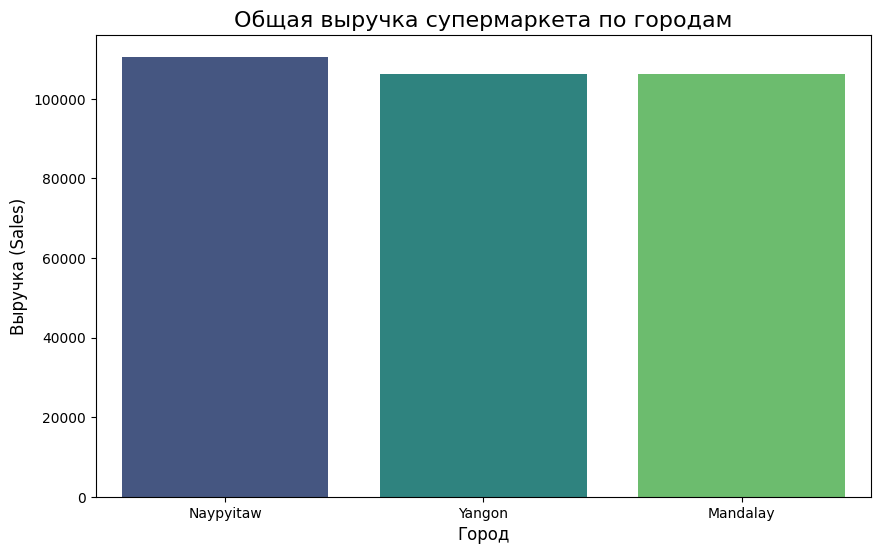


--- Выручка по категориям товаров ---


,Product line,Sales
2,Food and beverages,56144.8440
5,Sports and travel,55122.8265
0,Electronic accessories,54337.5315
1,Fashion accessories,54305.8950
4,Home and lifestyle,53861.9130
3,Health and beauty,49193.7390


In [1]:
# Импортируем библиотеки
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# 1. Загружаем файл с вашего компьютера
print("Пожалуйста, выберите ваш файл (SuperMarket Analysis.csv) в открывшемся окне:")
uploaded = files.upload()

# 2. Читаем загруженный файл в таблицу (pandas)
# Название файла должно совпадать с тем, что вы загрузили.
# Если в названии есть пробелы, напишите его в кавычках точно как оно есть.
import io
file_name = list(uploaded.keys())[0] # Эта строка сама находит имя файла
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

# 3. Смотрим на данные (первые 5 строк)
print("\n--- Первые 5 строк ---")
display(df.head())

# 4. Считаем общую выручку по городам
# ВАЖНО: Мы используем колонку 'Sales', так как именно она есть в вашем файле
sales_by_city = df.groupby('City')['Sales'].sum().reset_index()

# Сортируем по убыванию выручки, чтобы самый успешный город был первым
sales_by_city = sales_by_city.sort_values(by='Sales', ascending=False)

print("\n--- Общая выручка по городам (от большего к меньшему) ---")
display(sales_by_city)

# 5. Строим красивый график
plt.figure(figsize=(10, 6))
# Строим график по нашим сгруппированным данным
sns.barplot(x='City', y='Sales', data=sales_by_city, palette='viridis')

# Добавляем заголовок и подписи
plt.title('Общая выручка супермаркета по городам', fontsize=16)
plt.xlabel('Город', fontsize=12)
plt.ylabel('Выручка (Sales)', fontsize=12)

# Показываем график
plt.show()

# 6. Дополнительный анализ: Какая категория товаров принесла больше всего денег?
sales_by_product = df.groupby('Product line')['Sales'].sum().reset_index()
sales_by_product = sales_by_product.sort_values(by='Sales', ascending=False)

print("\n--- Выручка по категориям товаров ---")
display(sales_by_product)